# E/I modularity on the matched 150k set: RAW lesion drops

> **This is the raw-drop version of `ei_modularity_150k.ipynb`.** Everything (networks, clustering, wiring,
> figures) is identical, except the lesions: here a group's effect is the **raw drop** = intact accuracy −
> accuracy with the group silenced, as in Yang et al. (2019) Fig. 2e. There is **no random-lesion control**
> (the original subtracts the drop of random neurons of the same number and population).
>
> Consequences when comparing with the original notebook:
> * Large groups and I-rich groups show bigger drops simply because they are large / I-rich (in these networks
>   the raw drop tracks the number of silenced I neurons, ρ ≈ 0.7, and so does a random lesion of the same size).
> * Fragile tasks (DNMS, delay tasks) drop under almost any lesion, so they light up in many columns.
> * "Lesion hits own tasks (ρ)" and "mean |raw drop|" are computed on raw drops, so they are not the same numbers
>   as in the original.
> * Blue cells (negative drop) here mean the lesion actually *improved* that task, unlike the original where blue
>   meant "hurts less than a random lesion".

Four budgets trained the same way (`dale_all_woutfree_fanin_4pt_5seed_150k`: 150k steps, W_out trained, fanin
init, batched), 5 seeds each:

| point | rate budget | wiring budget |
|---|---|---|
| control | none | none |
| A3 (rate only) | 0.0011 | free |
| B0 (wiring only) | free | 0.0054 |
| C0 (both) | 0.0115 | 0.0044 |

The three kinds of modularity, and the views that tell them apart:

1. **E modules + shared inhibition**: I neurons broad, cluster poorly; no I↔E pairing in wiring.
2. **Mixed E+I modules**: each I group matches an E group's tasks and is wired to it (wiring vs similarity ρ > 0).
3. **Inhibition between modules**: I groups wired to E groups of *other* tasks (ρ < 0).

In [1]:
import contextlib, io
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import generate_trials, rule_name
from cmc.train_cog import (batch_accuracy, eval_config_from, load_checkpoint, response_mask, ring_prefs,
                           trial_to_tensors)

RUN = MOO_ZOOM_RUNS_DIR / "dale_all_rateray_woutfrozen_150k"
NETS = {
    "control": RUN / "control" / "seed_01.pt",
    "rate-limited (A0)": RUN / "A0" / "seed_00.pt",
    "wiring-limited (B0)": MOO_ZOOM_RUNS_DIR / "dale_all_wiringray_woutfrozen_150k" / "B0" / "seed_00.pt",
}
EVAL_SEEDS = (10000, 10001, 10002)   # fixed eval trials (first 3 of the front's 10 eval seeds)
BATCH = 64
N_RANDOM = 5                         # random lesions (same E and I counts) per cluster
SIL_REF = 0.2

In [2]:
def simulate(model, x, keep):
    # keep: (N,) tensor, 1 = normal, 0 = silenced
    x = model._normalize_input(x)
    B, _, T = x.shape
    h = torch.zeros(B, model.n_rnn)
    W = model.effective_w_rec()
    out = []
    for t in range(T):
        gate = x[:, :, t] @ model.w_in + h @ W + model.bias
        h = (1 - model.alpha) * h + model.alpha * model._cell_act(gate)
        h = h * keep
        out.append(torch.sigmoid(h[:, :model.n_e] @ model.w_out + model.b_out))
    return torch.stack(out, dim=1)


def cluster_units(tv, N):
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    norm = tv[:, active] / tv[:, active].max(0, keepdims=True)
    X = norm.T
    sil, labs = {}, {}
    for k in range(2, 21):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, 20) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get)
    lab = labs[K]
    # order clusters by preferred task so the plots read top-left to bottom-right
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    cluster = np.full(N, -1)
    cluster[np.flatnonzero(active)] = [order.index(c) for c in lab]
    return active, cluster, K, sil, local


def study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        acc = {}
        for rule in tasks:
            a = [batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
                 for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)]
            acc[rule] = float(np.mean(a))
        return pd.Series(acc)

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)                 # (tasks, units)
    active, cluster, K, sil, local = cluster_units(tv, N)
    is_E = np.arange(N) < N_E
    act_E, act_I = np.flatnonzero(active & is_E), np.flatnonzero(active & ~is_E)
    rng = np.random.default_rng(0)
    drop, rand_drop, rows = {}, {}, []
    for c in range(K):
        members = np.flatnonzero(cluster == c)
        nE, nI = int(is_E[members].sum()), int((~is_E[members]).sum())
        keep = torch.ones(N); keep[members] = 0
        drop[c + 1] = base - task_acc(keep)
        r = []
        for _ in range(N_RANDOM):
            keep = torch.ones(N)
            keep[np.r_[rng.choice(act_E, nE, replace=False), rng.choice(act_I, nI, replace=False)]] = 0
            r.append(base - task_acc(keep))
        rand_drop[c + 1] = pd.concat(r, axis=1).mean(axis=1)
        rows.append(dict(cluster=c + 1, units=len(members), E=nE, I=nI))
    D = pd.DataFrame(drop).T.rename(columns=rule_name)
    RD = pd.DataFrame(rand_drop).T.rename(columns=rule_name)
    info = pd.DataFrame(rows).set_index("cluster")
    summary = info.assign(**{
        "mean drop": D.mean(axis=1), "random mean drop": RD.mean(axis=1),
        "excess over random": D.mean(axis=1) - RD.mean(axis=1),
        "max drop": D.max(axis=1), "worst task": D.idxmax(axis=1),
        "max specific drop": (D - RD).max(axis=1), "on task": (D - RD).idxmax(axis=1),
        "specificity": D.max(axis=1) - D.mean(axis=1)})
    print(f"{name}: {ckpt.relative_to(MOO_ZOOM_RUNS_DIR)} | intact min {base.min():.3f}, mean {base.mean():.3f} | "
          f"{active.sum()} active units, k = {K}, silhouette {sil[K]:.3f} (local maxima {local})")
    return dict(name=name, tasks=tasks, N=N, N_E=N_E, tv=tv, base=base, active=active, cluster=cluster, K=K,
                sil=sil, local=local, D=D, RD=RD, info=info, summary=summary)


def plot_clusters(R):
    tv, cluster, K, N_E = R["tv"], R["cluster"], R["K"], R["N_E"]
    labels = [rule_name[t] for t in R["tasks"]]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[3.2, 1]))
    idx = np.flatnonzero(R["active"])
    idx = idx[np.lexsort((idx >= N_E, cluster[idx]))]
    ax.imshow((tv / np.maximum(tv.max(0, keepdims=True), 1e-30))[:, idx], cmap="hot", aspect="auto",
              interpolation="nearest", vmin=0, vmax=1)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_xticks([])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for c in range(K):
        pos = np.flatnonzero(cluster[idx] == c)
        ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                solid_capstyle="butt")
        ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
    ax.set_ylim(len(labels) - .5, -.5)
    ax.set_title(f"{R['name']}: task variance, units grouped by cluster (k = {K})", fontsize=9)
    sil, local = R["sil"], R["local"]
    ax2.plot(list(sil), list(sil.values()), "o-", ms=3)
    ax2.scatter(local, [sil[k] for k in local], s=60, facecolors="none", edgecolors="orange", label="local maxima")
    ax2.axvline(K, color="orange", ls="--", lw=1); ax2.axhline(SIL_REF, color="k", ls="--", lw=1)
    ax2.set_xlabel("k"); ax2.set_ylabel("silhouette"); ax2.legend(fontsize=7)
    plt.tight_layout(); plt.show()


def lesion_panel(ax, M, info, cmap, lim, title, annotate):
    # tasks on y, clusters on x; each cluster's column is as wide as its number of units (like the TV heatmap)
    edges = np.r_[0, np.cumsum(info.units.values)]
    tasks = list(M.columns)
    im = ax.pcolormesh(edges, np.arange(len(tasks) + 1) - 0.5, M.values.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
    for x in edges[1:-1]:
        ax.axvline(x, color="k", lw=0.6)
    centres = (edges[:-1] + edges[1:]) / 2
    if annotate:
        for j, (c, w) in enumerate(zip(centres, info.units.values)):
            for i, v in enumerate(M.values[j]):
                if abs(v) >= 0.1 and w >= 6:
                    ax.text(c, i, f"{v:.2f}", ha="center", va="center", fontsize=6 if w >= 12 else 5)
    ax.set_yticks(range(len(tasks))); ax.set_yticklabels(tasks, fontsize=7)
    ax.set_ylim(len(tasks) - 0.5, -0.5)
    ax.set_xticks(centres)
    ax.set_xticklabels([f"{c}" for c in info.index], fontsize=7)
    ax.set_xlabel("cluster (column width = number of units)", fontsize=8)
    ax.set_title(title, fontsize=10)
    return im


def plot_lesions(R):
    D, RD, info = R["D"], R["RD"], R["info"]
    vmax = max(0.5, D.values.max())
    # small: the two raw drops
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    for ax, M, title in [(axes[0], D, "accuracy drop when the cluster is silenced"),
                         (axes[1], RD, f"random lesion, same E and I counts (mean of {N_RANDOM})")]:
        im = lesion_panel(ax, M, info, "Reds", (0, vmax), title, annotate=False)
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="accuracy drop")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()
    # big: specific drop
    fig, ax = plt.subplots(figsize=(15, 6.5))
    im = lesion_panel(ax, D - RD, info, "RdBu_r", (-0.5, 0.5),
                      f"{R['name']}: specific drop = cluster silenced − random (same E/I counts); "
                      f"red = the cluster matters for this task more than any group of its size", annotate=True)
    ax.set_xticklabels([f"{c}\n{r.units} u\n{r.E}E {r.I}I" for c, r in info.iterrows()], fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="specific accuracy drop")
    plt.tight_layout(); plt.show()

In [3]:
from scipy.stats import spearmanr

N_SHUFFLE = 500
PRESENT = 1e-2          # a synapse is present if its E/I-normalised |w| is above this (the conn_frac threshold)


def cluster_pop(norm, k_max):
    # norm: (tasks, units) of one population, each unit divided by its own max. Local-max rule, k > 2.
    X = norm.T
    k_max = min(k_max, len(X) - 1)
    sil, labs = {}, {}
    for k in range(2, k_max + 1):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, k_max) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get) if local else max(sil, key=sil.get)
    lab = labs[K]
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    return np.array([order.index(c) for c in lab]), K, sil, local


def ei_study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        return pd.Series({rule: float(np.mean([
            batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
            for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)])) for rule in tasks})

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    normfull = tv / np.maximum(tv.max(0, keepdims=True), 1e-30)
    out = dict(name=name, tasks=tasks, base=base, N=N, N_E=N_E, normfull=normfull)
    for pop, sel, k_max in (("E", np.arange(N) < N_E, 20), ("I", np.arange(N) >= N_E, 10)):
        units = np.flatnonzero(active & sel)
        lab, K, sil, local = cluster_pop(normfull[:, units], k_max)
        prof = np.stack([normfull[:, units[lab == c]].mean(axis=1) for c in range(K)])     # (K, tasks)
        breadth = (normfull[:, units] > 0.5).sum(0)                                       # tasks per neuron
        out[pop] = dict(units=units, lab=lab, K=K, sil=sil, local=local, prof=prof, breadth=breadth,
                        sizes=np.bincount(lab, minlength=K))

    # --- wiring between I groups and E groups (mean |w|, pruned = 0), z-scored against shuffled group labels
    W = model.effective_w_rec().detach().numpy()
    scale = model.ei_row_scale().detach().numpy()[:, None]
    A = np.where(np.abs(W) / scale > PRESENT, np.abs(W), 0.0)
    E, I = out["E"], out["I"]

    def blocks(labE, labI):
        GE = np.eye(E["K"])[labE]          # (nE, KE)
        GI = np.eye(I["K"])[labI]
        A_IE = A[np.ix_(I["units"], E["units"])]
        A_EI = A[np.ix_(E["units"], I["units"])]
        nE, nI = GE.sum(0), GI.sum(0)
        return (GI.T @ A_IE @ GE) / np.outer(nI, nE), (GE.T @ A_EI @ GI) / np.outer(nE, nI)

    IE, EI = blocks(E["lab"], I["lab"])
    rng = np.random.default_rng(0)
    nulls = [blocks(rng.permutation(E["lab"]), rng.permutation(I["lab"])) for _ in range(N_SHUFFLE)]
    nIE, nEI = np.array([n[0] for n in nulls]), np.array([n[1] for n in nulls])
    out["IE_z"] = (IE - nIE.mean(0)) / np.maximum(nIE.std(0), 1e-12)          # (KI, KE)
    out["EI_z"] = (EI - nEI.mean(0)) / np.maximum(nEI.std(0), 1e-12)          # (KE, KI)
    out["sim"] = np.corrcoef(np.vstack([I["prof"], E["prof"]]))[:I["K"], I["K"]:]   # (KI, KE) task-profile r

    # --- lesions: each E group alone, each I group alone; RAW drop (as Yang 2019), no random control
    for pop in ("E", "I"):
        P = out[pop]
        drop = {}
        for c in range(P["K"]):
            members = P["units"][P["lab"] == c]
            keep = torch.ones(N); keep[members] = 0
            drop[c + 1] = base - task_acc(keep)
        P["D"] = pd.DataFrame(drop).T.rename(columns=rule_name)
        P["spec"] = P["D"]                       # raw drop = intact accuracy - lesioned accuracy
        # does silencing a group hurt its OWN tasks? r(raw drop over tasks, the group's task profile)
        P["own_r"] = np.array([spearmanr(P["spec"].values[c], P["prof"][c])[0] for c in range(P["K"])])
    print(f"{name}: E {len(E['units'])} active, k = {E['K']} (sil {E['sil'][E['K']]:.3f}); "
          f"I {len(I['units'])} active, k = {I['K']} (sil {I['sil'][I['K']]:.3f})")
    return out


def plot_ei(R):
    E, I, labels = R["E"], R["I"], [rule_name[t] for t in R["tasks"]]
    # (a) task variance of E and I separately, units grouped by their own clusters; silhouette curves
    fig = plt.figure(figsize=(20, 4.8))
    gsp = fig.add_gridspec(1, 4, width_ratios=[len(E["units"]), max(len(I["units"]), 40), 45, 45])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[j])
        o = np.argsort(P["lab"], kind="stable")
        ax.imshow(R["normfull"][:, P["units"][o]], cmap="hot", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels if j == 0 else [], fontsize=7); ax.set_xticks([])
        labs = P["lab"][o]
        for c in range(P["K"]):
            pos = np.flatnonzero(labs == c)
            ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                    solid_capstyle="butt")
            ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
        ax.set_ylim(len(labels) - .5, -.5)
        ax.set_title(f"{pop} units ({len(P['units'])} active): k = {P['K']}, silhouette {P['sil'][P['K']]:.2f}\n"
                     f"tasks per neuron (norm. TV > 0.5): {P['breadth'].mean():.1f}", fontsize=9)
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[2 + j])
        ax.plot(list(P["sil"]), list(P["sil"].values()), "o-", ms=3)
        ax.axvline(P["K"], color="orange", ls="--", lw=1); ax.axhline(SIL_REF, color="k", ls="--", lw=1)
        ax.set_title(f"{pop}: silhouette vs k", fontsize=9); ax.set_xlabel("k")
    fig.suptitle(R["name"] + ": E and I clustered separately", fontsize=11)
    plt.tight_layout(); plt.show()

    # (b) task-profile similarity and wiring, I groups (rows) x E groups (cols)
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.35 * I["K"] + 3.2))
    xl = [f"E{c + 1}\n{n}" for c, n in enumerate(E["sizes"])]
    yl = [f"I{c + 1} ({n})" for c, n in enumerate(I["sizes"])]
    for ax, M, title, lim in [(axes[0], R["sim"], "task-profile similarity (r) of I group and E group", 1),
                              (axes[1], R["IE_z"], "I → E wiring (z vs shuffled groups)", 4),
                              (axes[2], R["EI_z"].T, "E → I wiring (z vs shuffled groups)", 4)]:
        im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for (i, j), v in np.ndenumerate(M):
            if abs(v) >= (0.5 if lim == 1 else 2):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
        ax.set_xticks(range(E["K"])); ax.set_xticklabels(xl, fontsize=6)
        ax.set_yticks(range(I["K"])); ax.set_yticklabels(yl, fontsize=7)
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    fig.suptitle(R["name"] + ": do I groups pair with E groups that do the same tasks, and are they wired to them?",
                 fontsize=11)
    plt.tight_layout(); plt.show()

    # (c) raw drop (intact - group silenced), tasks on y, width = size
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=[2.2, 1]))
    for ax, (pop, P) in zip(axes, (("E", E), ("I", I))):
        info = pd.DataFrame({"units": P["sizes"]}, index=range(1, P["K"] + 1))
        im = lesion_panel(ax, P["spec"], info, "RdBu_r", (-0.5, 0.5),
                          f"{pop} groups silenced alone: raw accuracy drop (intact − lesioned)", annotate=True)
        ax.set_xticklabels([f"{pop}{c}\n{n}" for c, n in info.units.items()], fontsize=7)
        if pop == "I":
            ax.set_yticklabels([])
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="raw accuracy drop (red = worse)")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()


def ei_summary(R):
    E, I = R["E"], R["I"]
    pairs_IE = spearmanr(R["sim"].ravel(), R["IE_z"].ravel())[0]
    pairs_EI = spearmanr(R["sim"].ravel(), R["EI_z"].T.ravel())[0]
    return {
        "E: tasks per neuron": E["breadth"].mean(), "I: tasks per neuron": I["breadth"].mean(),
        "E silhouette": E["sil"][E["K"]], "I silhouette": I["sil"][I["K"]],
        "best E match per I group (mean r)": R["sim"].max(axis=1).mean(),
        "I→E wiring vs similarity (ρ)": pairs_IE, "E→I wiring vs similarity (ρ)": pairs_EI,
        "I lesion hits own tasks (mean ρ)": np.nanmean(I["own_r"]),
        "E lesion hits own tasks (mean ρ)": np.nanmean(E["own_r"]),
        "I groups, mean |raw drop|": I["spec"].abs().values.mean(),
        "E groups, mean |raw drop|": E["spec"].abs().values.mean(),
    }

## 1. Run all 20 networks

About 20 s per network (no random lesions).

In [4]:
RUN150 = MOO_ZOOM_RUNS_DIR / "dale_all_woutfree_fanin_4pt_5seed_150k"
POINTS = ["control", "A3", "B0", "C0"]
LABEL = {"control": "control", "A3": "A3 rate only", "B0": "B0 wiring only", "C0": "C0 both"}
runs150 = pd.read_csv(RUN150 / "runs.csv")
ALL = {}
for p in POINTS:
    for s in range(5):
        ALL[p, s] = ei_study(f"{LABEL[p]} seed {s} (raw drop)", RUN150 / p / f"seed_{s:02d}.pt")

control seed 0 (raw drop): E 204 active, k = 6 (sil 0.169); I 52 active, k = 3 (sil 0.211)


control seed 1 (raw drop): E 203 active, k = 6 (sil 0.171); I 51 active, k = 8 (sil 0.223)


control seed 2 (raw drop): E 204 active, k = 7 (sil 0.193); I 51 active, k = 8 (sil 0.249)


control seed 3 (raw drop): E 204 active, k = 10 (sil 0.189); I 52 active, k = 4 (sil 0.247)


control seed 4 (raw drop): E 204 active, k = 4 (sil 0.212); I 52 active, k = 3 (sil 0.266)


...

C0 both seed 1 (raw drop): E 160 active, k = 14 (sil 0.246); I 46 active, k = 9 (sil 0.215)


C:\Users\athar\AppData\Local\Temp\ipykernel_2116\1281711360.py:90: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  P["own_r"] = np.array([spearmanr(P["spec"].values[c], P["prof"][c])[0] for c in range(P["K"])])


C0 both seed 2 (raw drop): E 176 active, k = 10 (sil 0.226); I 45 active, k = 9 (sil 0.263)


C0 both seed 3 (raw drop): E 157 active, k = 12 (sil 0.235); I 42 active, k = 4 (sil 0.271)


C0 both seed 4 (raw drop): E 145 active, k = 13 (sil 0.243); I 43 active, k = 5 (sil 0.240)


## 2. All 20 networks: the summary numbers

One row per network. Lesion numbers are on raw drops. The figure shows each number by point (dots = seeds,
bar = mean).

In [5]:
rows = []
for (p, s), R in ALL.items():
    acc = runs150[(runs150.point == p) & (runs150.seed == s)].min_task_acc.iloc[0]
    rows.append({"point": p, "seed": s, "min_task_acc": acc, "E groups": R["E"]["K"], "I groups": R["I"]["K"],
                 **ei_summary(R)})
T = pd.DataFrame(rows)
T.to_csv("ei_modularity_150k_rawdrop_summary.csv", index=False)
display(T.round(3))
display(T.drop(columns="seed").groupby("point", sort=False).agg(["mean", "std"]).round(3).T)

,point,seed,min_task_acc,E groups,I groups,E: tasks per neuron,I: tasks per neuron,E silhouette,I silhouette,best E match per I group (mean r),I→E wiring vs similarity (ρ),E→I wiring vs similarity (ρ),I lesion hits own tasks (mean ρ),E lesion hits own tasks (mean ρ),"I groups, mean |raw drop|","E groups, mean |raw drop|"
0,control,0,0.964,6,3,4.691,4.635,0.169,0.211,0.872,-0.467,-0.123,0.289,0.600,0.489,0.209
1,control,1,0.975,6,8,4.798,4.431,0.171,0.223,0.695,-0.390,0.105,0.492,0.692,0.169,0.187
2,control,2,0.939,7,8,4.515,5.118,0.193,0.249,0.721,-0.317,0.118,0.503,0.648,0.124,0.136
3,control,3,0.970,10,4,4.775,5.058,0.189,0.247,0.866,-0.328,0.202,0.501,0.549,0.385,0.103
4,control,4,0.955,4,3,4.725,4.904,0.212,0.266,0.940,-0.713,-0.126,0.123,0.338,0.546,0.281
5,A3,0,0.747,7,6,3.288,4.231,0.277,0.368,0.815,0.041,0.086,0.613,0.498,0.069,0.045
6,A3,1,0.855,8,5,2.917,4.115,0.281,0.305,0.756,-0.013,-0.153,0.763,0.544,0.086,0.036
7,A3,2,0.928,11,6,2.737,4.019,0.291,0.305,0.832,-0.031,0.152,0.452,0.645,0.077,0.032
8,A3,3,0.962,13,3,2.918,4.519,0.287,0.330,0.770,0.009,-0.012,0.671,0.518,0.214,0.025
9,A3,4,0.781,16,9,2.646,3.788,0.257,0.215,0.782,0.056,-0.015,0.576,0.503,0.047,0.024


point                                   control      A3     B0      C0
min_task_acc                      mean    0.961   0.855  0.874   0.876
                                  std     0.014   0.092  0.068   0.027
E groups                          mean    6.600  11.000  7.000  13.600
                                  std     2.191   3.674  6.164   3.362
I groups                          mean    5.200   5.800  5.000   7.200
                                  std     2.588   2.168  1.871   2.490
E: tasks per neuron               mean    4.701   2.901  5.153   3.522
                                  std     0.112   0.246  0.292   0.168
I: tasks per neuron               mean    4.829   4.135  4.831   3.975
                                  std     0.290   0.270  0.602   0.346
E silhouette                      mean    0.187   0.279  0.226   0.235
                                  std     0.018   0.013  0.030   0.010
I silhouette                      mean    0.239   0.305  0.240   0.259
                                  std     0.022   0.056  0.028   0.034
best E match per I group (mean r) mean    0.819   0.791  0.737   0.788
                                  std     0.106   0.032  0.046   0.071
I→E wiring vs similarity (ρ)      mean   -0.443   0.012  0.186   0.175
                                  std     0.162   0.036  0.193   0.092
E→I wiring vs similarity (ρ)      mean    0.035   0.011  0.202   0.458
                                  std     0.150   0.116  0.168   0.125
I lesion hits own tasks (mean ρ)  mean    0.382   0.615  0.345   0.460
                                  std     0.171   0.115  0.062   0.050
E lesion hits own tasks (mean ρ)  mean    0.566   0.542  0.434   0.495
                                  std     0.138   0.061  0.061   0.083
I groups, mean |raw drop|         mean    0.343   0.099  0.331   0.143
                                  std     0.189   0.066  0.102   0.060
E groups, mean |raw drop|         mean    0.183   0.032  0.262   0.086
                                  std     0.069   0.009  0.116   0.021

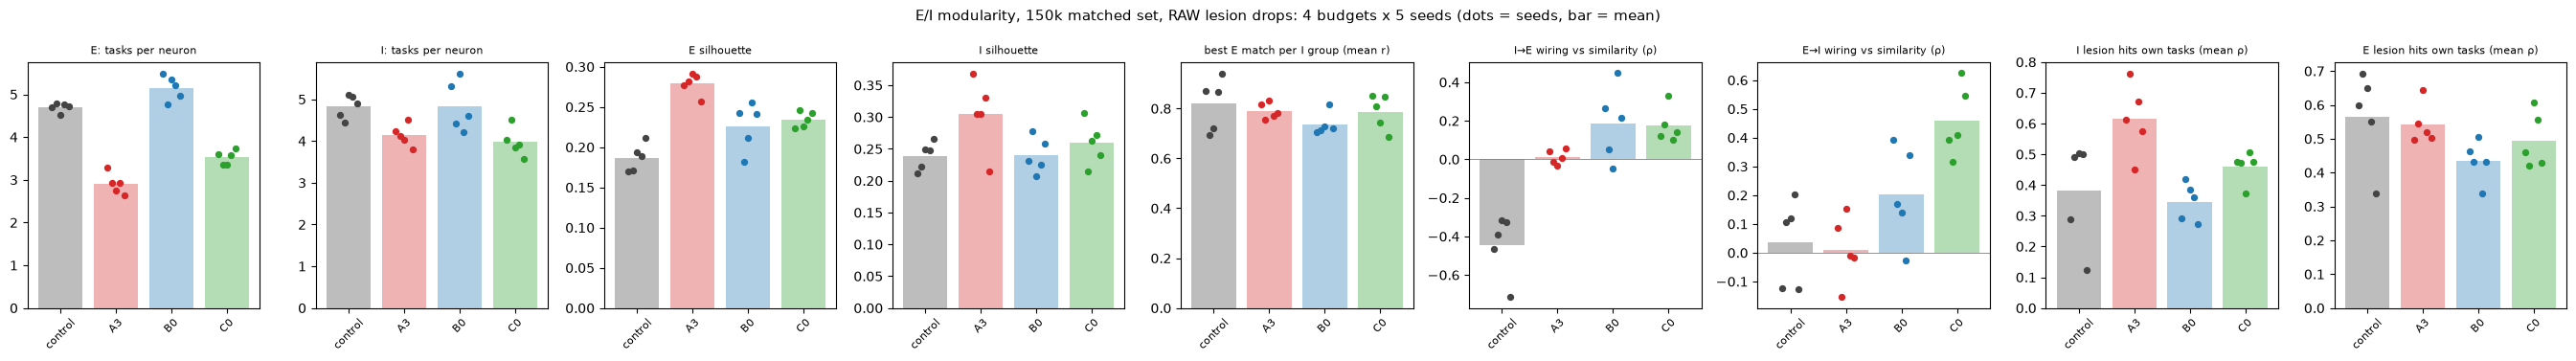

In [6]:
metrics = ["E: tasks per neuron", "I: tasks per neuron", "E silhouette", "I silhouette",
           "best E match per I group (mean r)", "I→E wiring vs similarity (ρ)", "E→I wiring vs similarity (ρ)",
           "I lesion hits own tasks (mean ρ)", "E lesion hits own tasks (mean ρ)"]
fig, axes = plt.subplots(1, len(metrics), figsize=(3.0 * len(metrics), 3.8))
pc = dict(zip(POINTS, ["#444444", "#d62728", "#1f77b4", "#2ca02c"]))
for ax, m in zip(axes, metrics):
    for i, p in enumerate(POINTS):
        v = T[T.point == p][m].values
        ax.bar(i, np.nanmean(v), color=pc[p], alpha=0.35)
        ax.scatter(np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), v, color=pc[p], s=18, zorder=3)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xticks(range(len(POINTS))); ax.set_xticklabels(POINTS, rotation=45, fontsize=8)
    ax.set_title(m, fontsize=8)
fig.suptitle("E/I modularity, 150k matched set, RAW lesion drops: 4 budgets x 5 seeds (dots = seeds, bar = mean)",
             fontsize=11)
plt.tight_layout(); plt.show()

## 3. Details for the best seed of each point (highest min_task_acc)

For each: E and I task variance clustered separately; I group × E group task similarity and wiring; **raw**
accuracy drop when one E group or one I group is silenced alone (red = the task gets worse).

### control

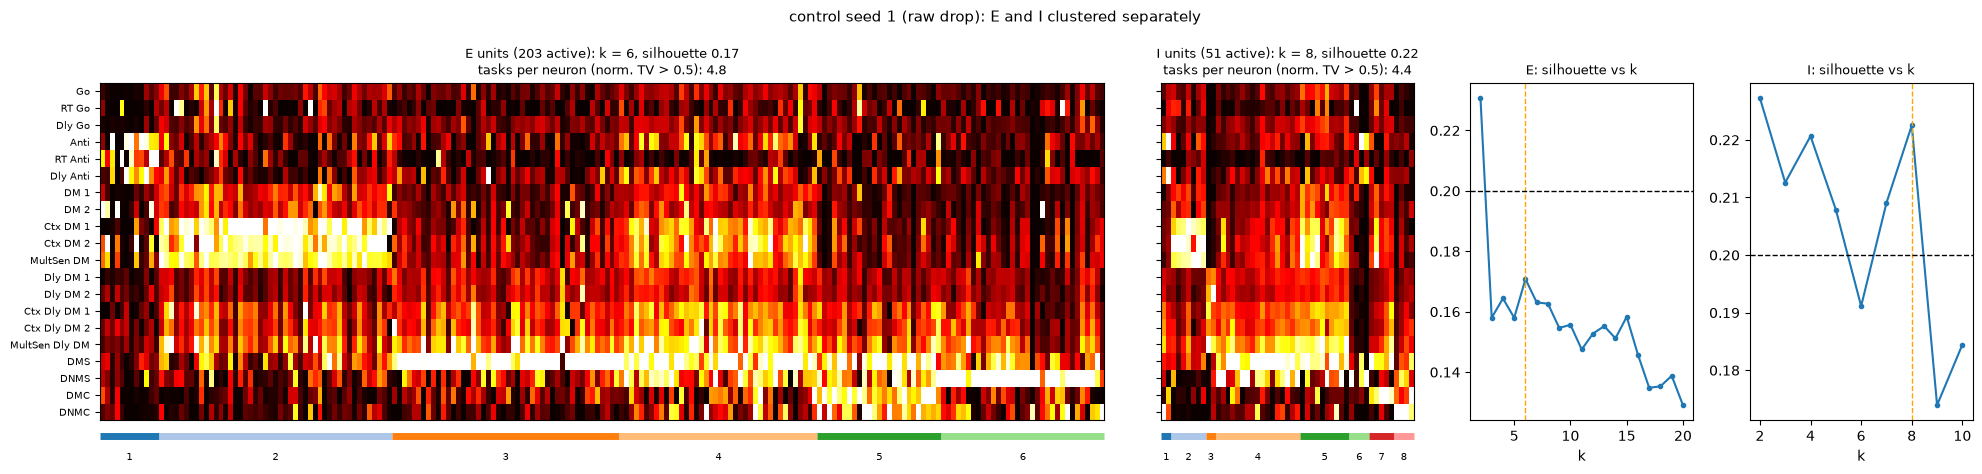

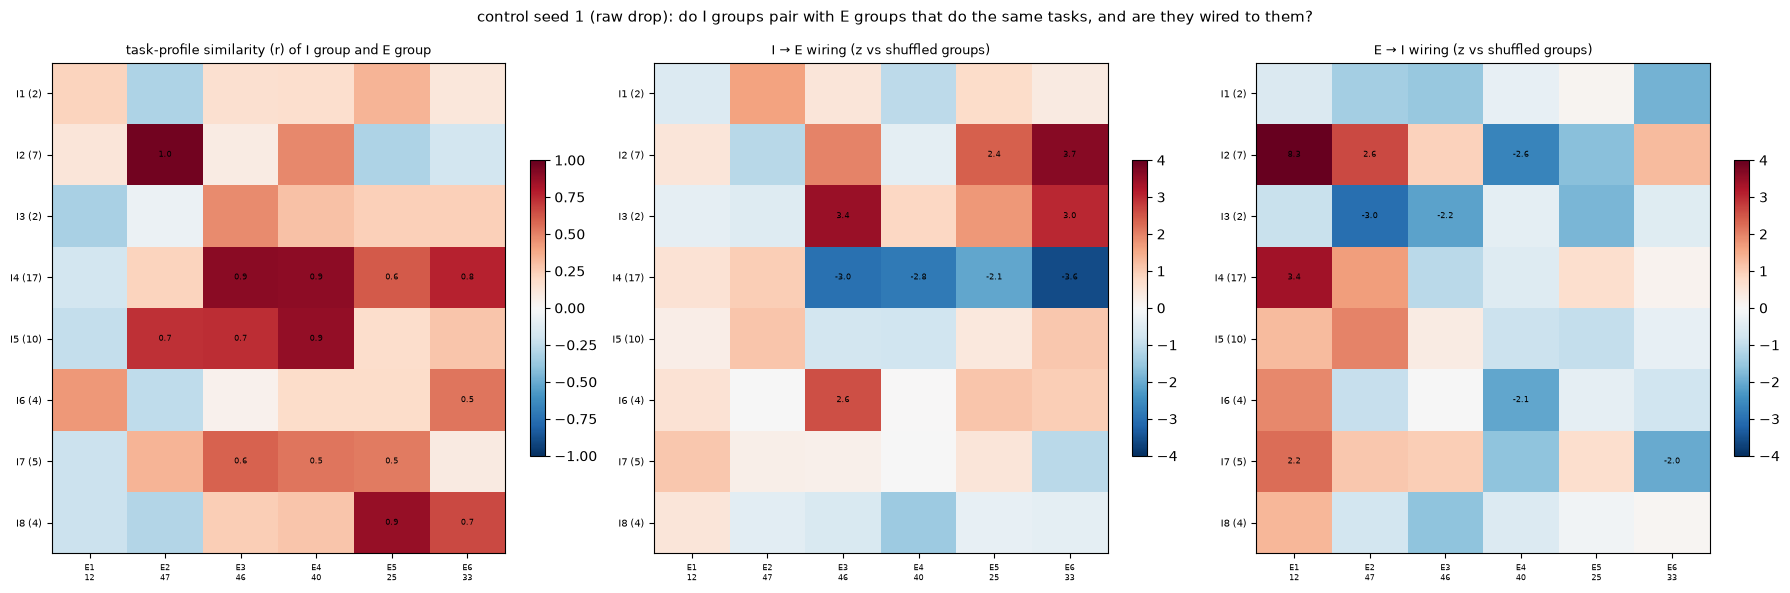

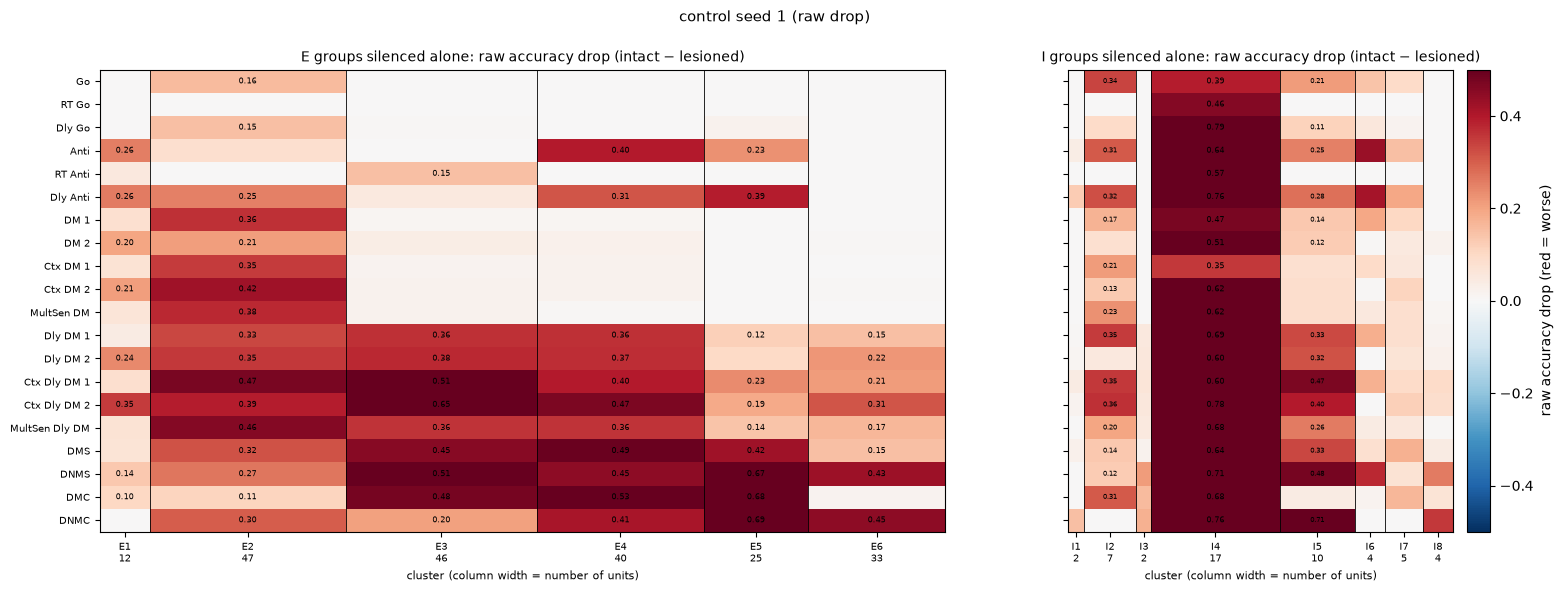

In [7]:
s = int(runs150[runs150.point == "control"].sort_values("min_task_acc").seed.iloc[-1])
plot_ei(ALL["control", s])

### A3

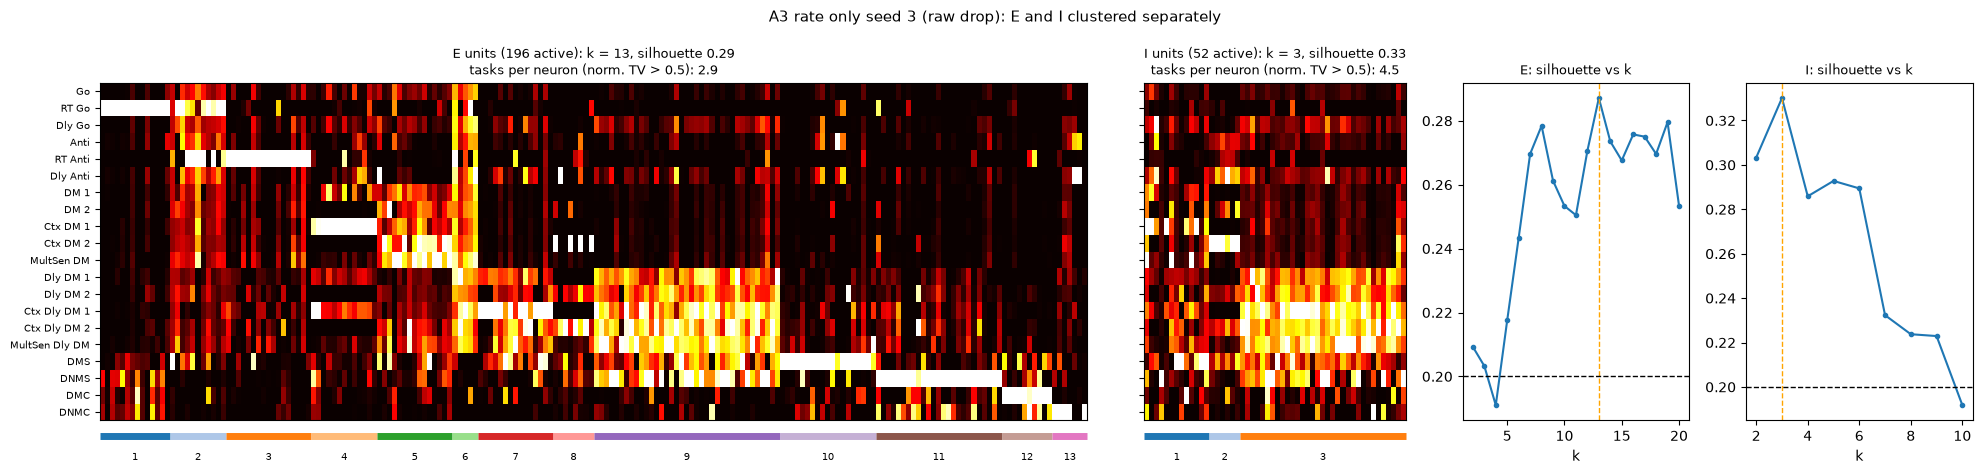

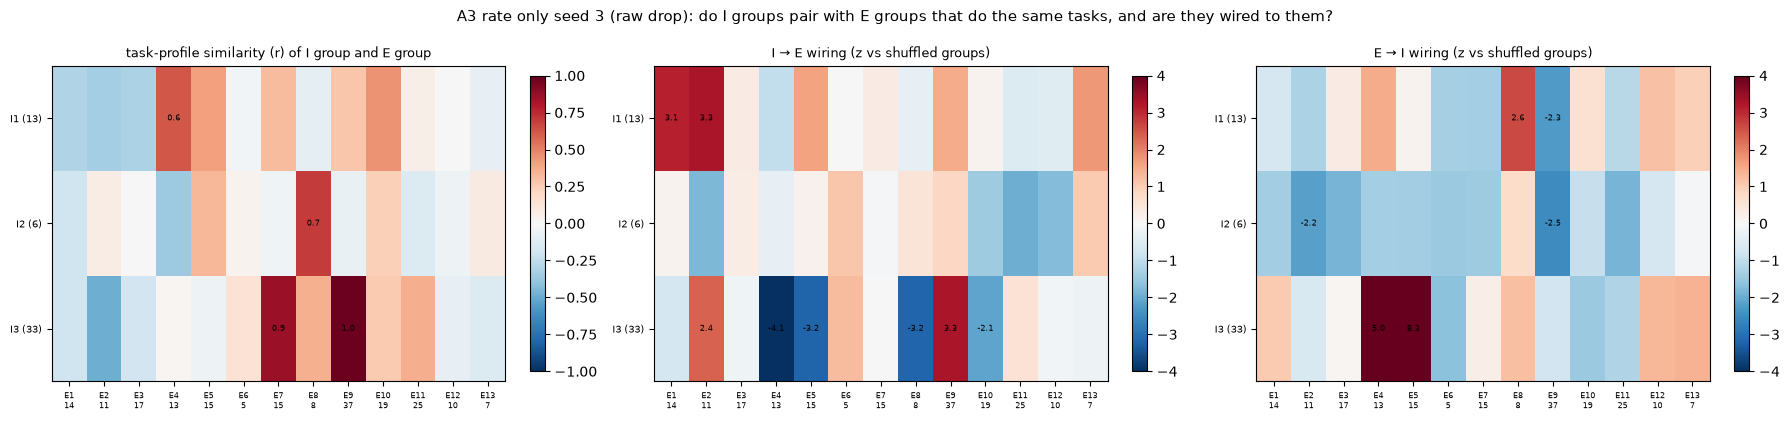

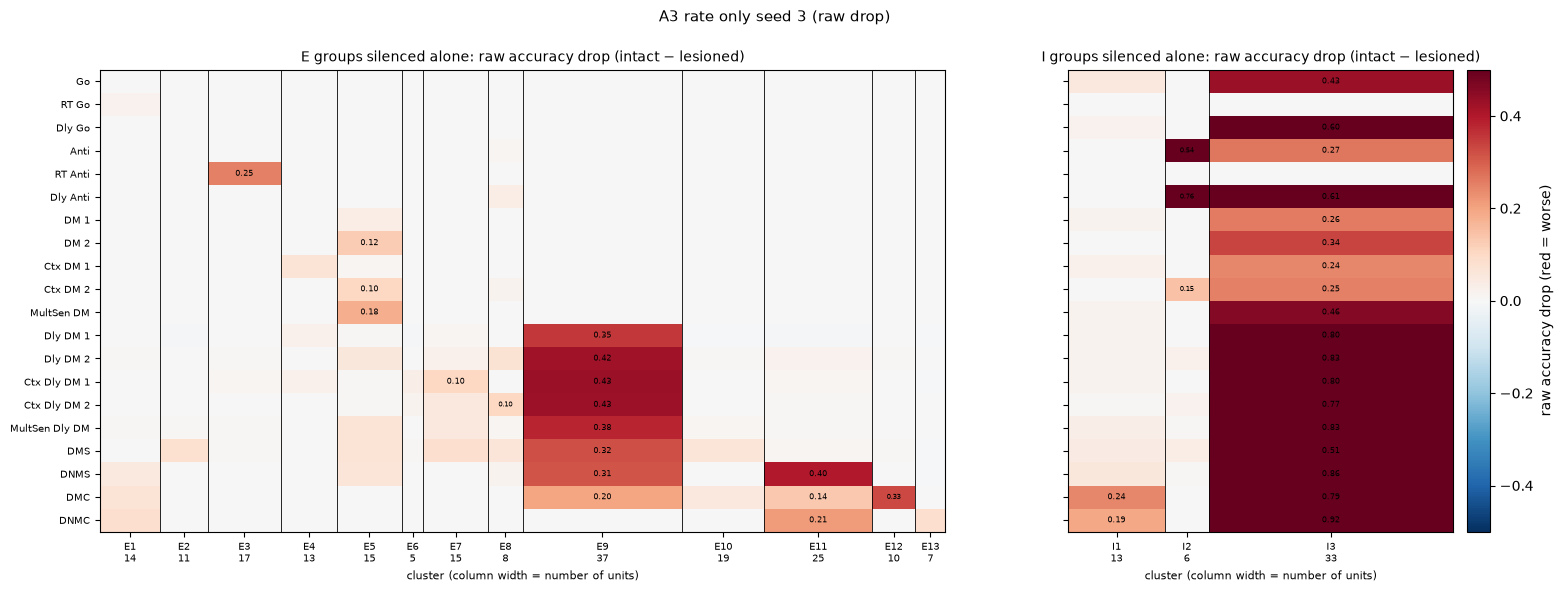

In [8]:
s = int(runs150[runs150.point == "A3"].sort_values("min_task_acc").seed.iloc[-1])
plot_ei(ALL["A3", s])

### B0

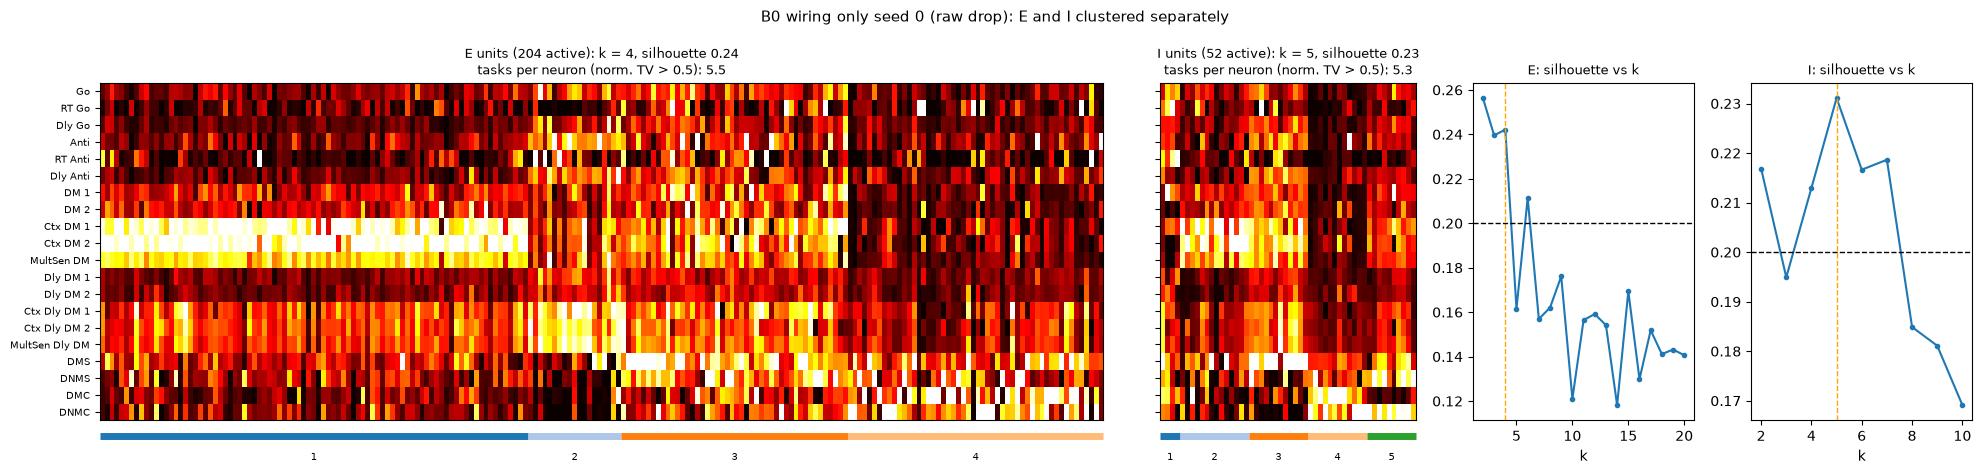

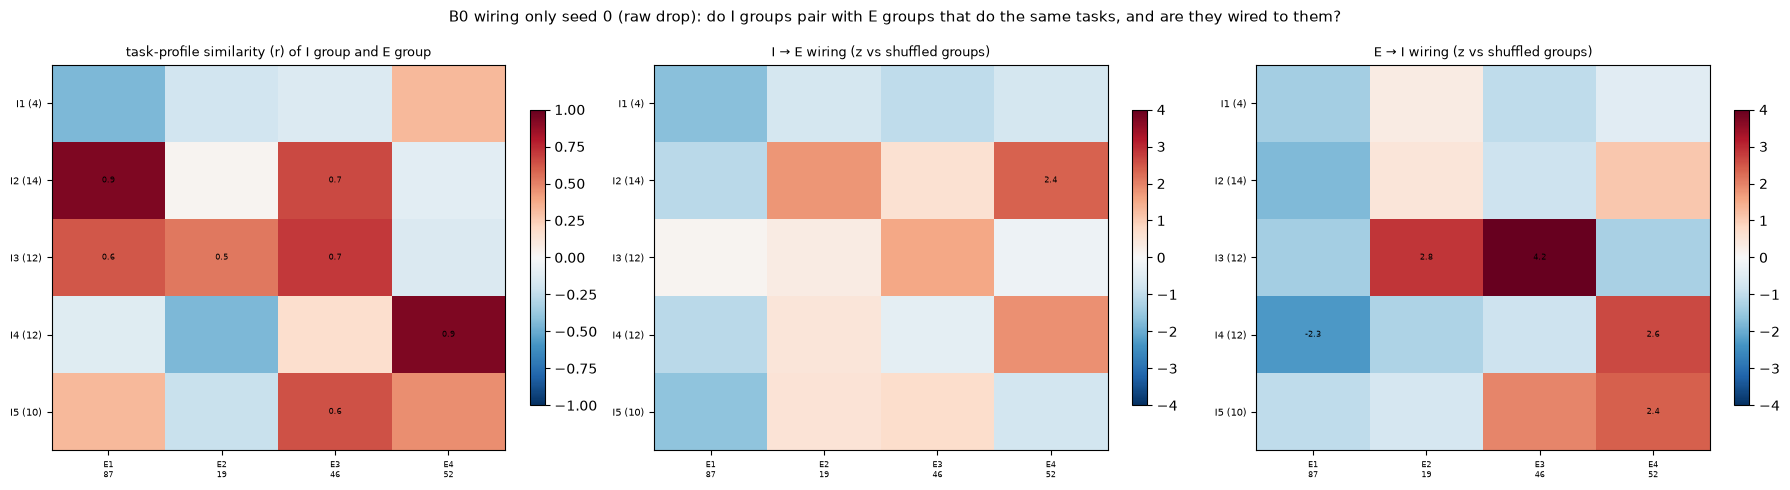

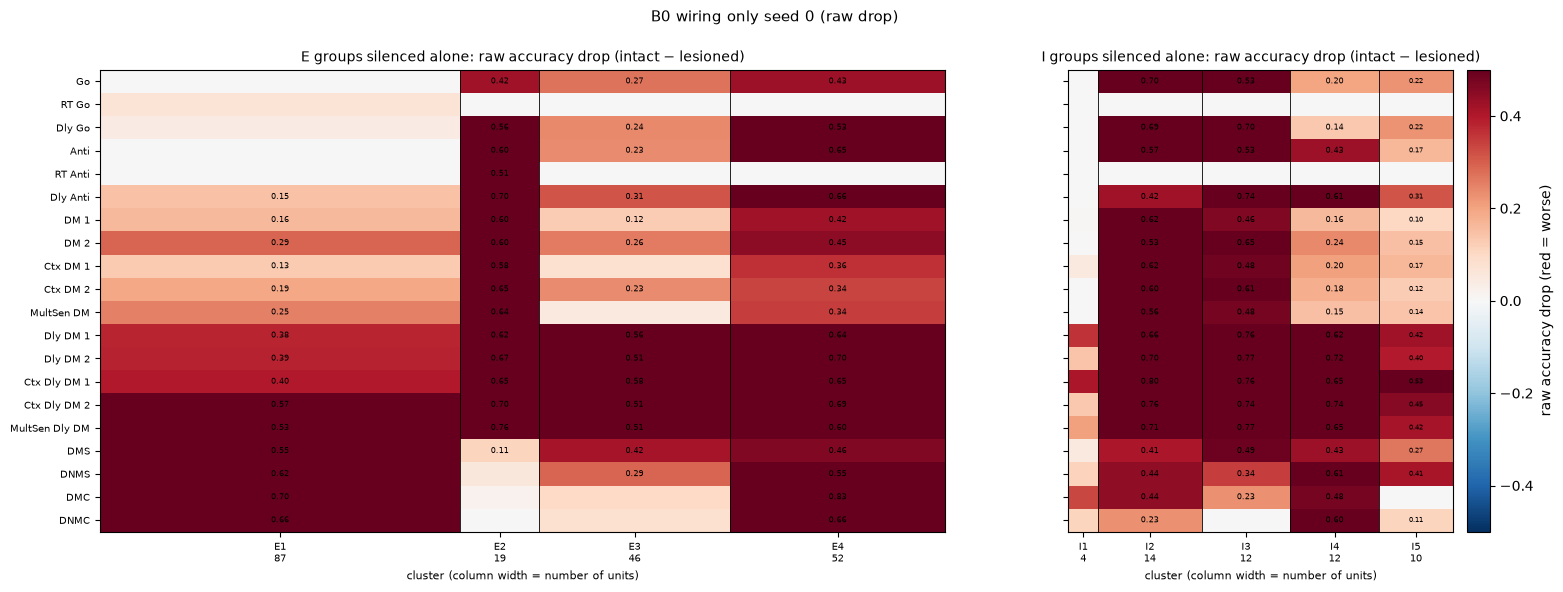

In [9]:
s = int(runs150[runs150.point == "B0"].sort_values("min_task_acc").seed.iloc[-1])
plot_ei(ALL["B0", s])

### C0

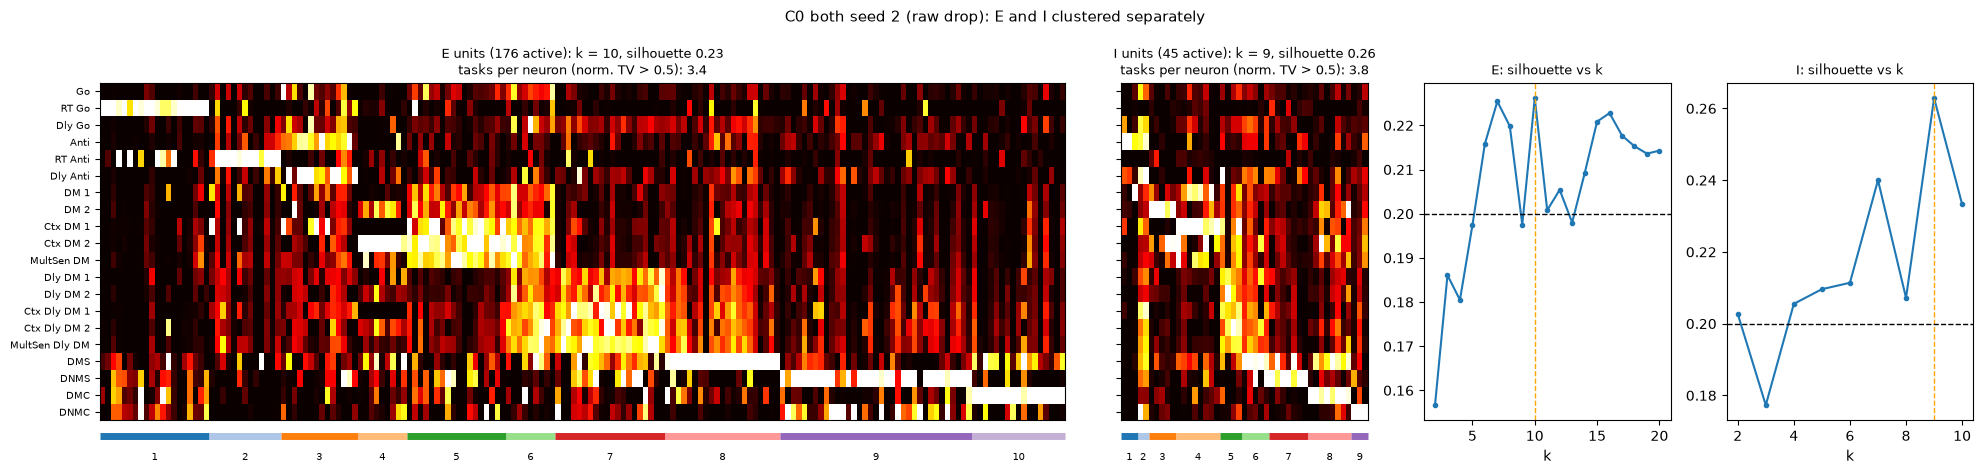

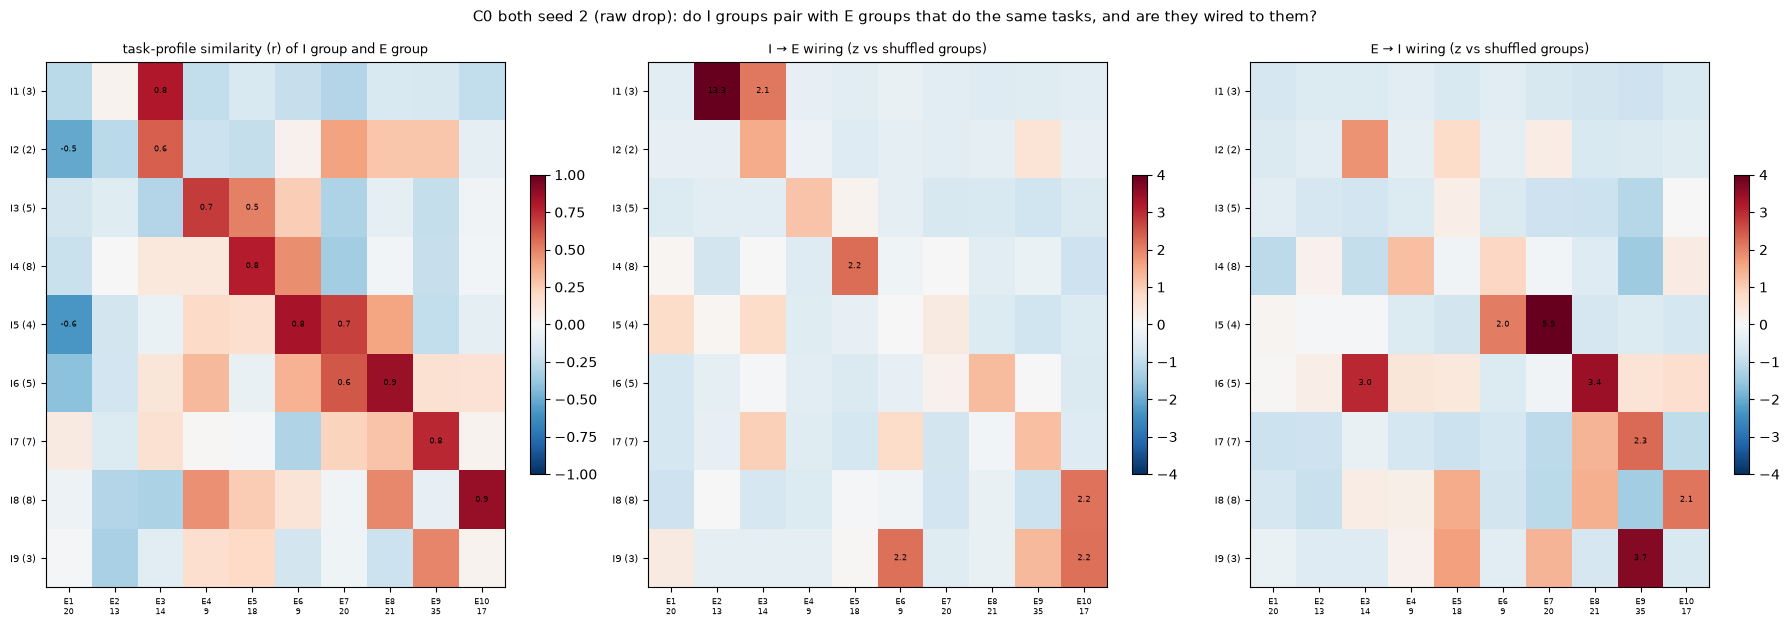

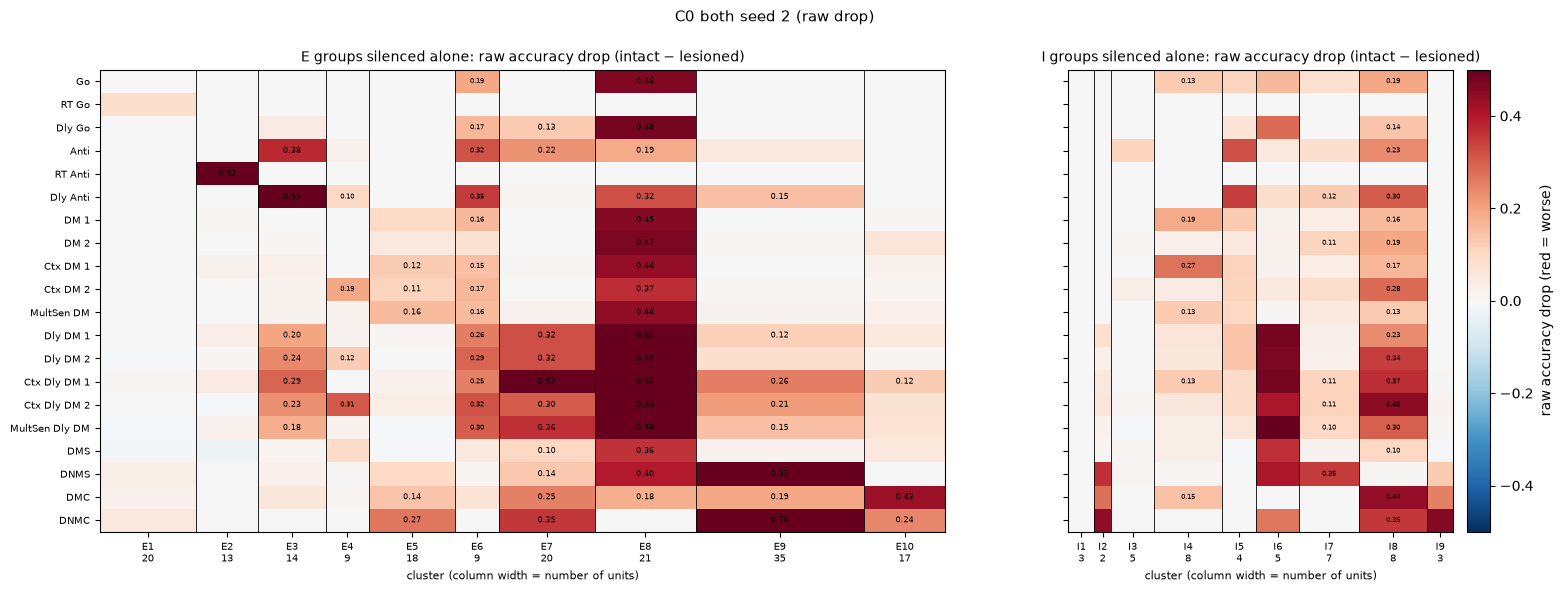

In [10]:
s = int(runs150[runs150.point == "C0"].sort_values("min_task_acc").seed.iloc[-1])
plot_ei(ALL["C0", s])

## 4. Reading it

*(to be written; see the outputs above)*